<a href="https://colab.research.google.com/github/jhovasnh06-beep/Metodos-Numericos-1/blob/main/notebooks_MetodoNeville.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Método de Interpolación Iterada de Neville

Dado un conjunto de $n + 1$ puntos distintos $(x_0, f(x_0)), (x_1, f(x_1)), \dots, (x_n, f(x_n))$, el algoritmo de Neville genera de forma recursiva aproximaciones polinomiales de grado sucesivo evaluadas en un punto objetivo $x$, sin necesidad de construir explícitamente el polinomio completo.

La relación de recurrencia para calcular cada entrada $Q_{i,j}$ de la tabla es:

$$Q_{i,j} = \frac{(x - x_{i-j}) Q_{i,j-1} - (x - x_i) Q_{i-1,j-1}}{x_i - x_{i-j}}$$

para $i = 1, 2, \dots, n$ y $j = 1, 2, \dots, i$, tomando como valores iniciales $Q_{i,0} = f(x_i)$. El valor final aproximado corresponde a $P(x) = Q_{n,n}$.

Ejemplo 2
Aproximar $f(1.5)$ usando los datos de la Tabla 3.5:
* $x = [1.0, 1.3, 1.6, 1.9, 2.2]$
* $f(x) = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]$

Importamos las librerías

In [ ]:
import numpy as np                  # Para crear la matriz Q
import pandas as pd                 # Para imprimir la tabla de Neville
import sympy as sp                  # Para sacar el polinomio
from scipy.interpolate import barycentric_interpolate  # Para validar con SciPy
import matplotlib.pyplot as plt     # Para graficar los nodos y el polinomio

Datos

In [ ]:
x_nodos = np.array([1.0, 1.3, 1.6, 1.9, 2.2])
y_nodos = np.array([0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623])
x_eval = 1.5

Definimos

In [ ]:
def metodo_neville(x, xi, yi):
    n = len(xi) - 1 #total de puntos (n+1)-1 para tener n
    Q = np.zeros((n + 1, n + 1))  # Crea una matriz cuadrada de ceros de tamaño (n+1) x (n+1)
    Q[:, 0] = yi #Para llenar la primer columna (j=0) con los valores iniciales y ":" para seleccionar todas las filas de la columna 0
    for i in range(1, n + 1):
        for j in range(1, i + 1): #para que vaya desde 1 hasta (n+1)
            num = (x - xi[i - j]) * Q[i, j - 1] - (x - xi[i]) * Q[i - 1, j - 1]
            den = xi[i] - xi[i - j]
            Q[i, j] = num / den

    # Regresamos toda la tabla Q y el último elemento Q[n, n]
    return Q, Q[n, n] #regresa la tabla Q y el último elemento

# Ejecutar la función
tabla_Q, aproximacion = metodo_neville(x_eval, x_nodos, y_nodos)

Podemos visualizar la tabla

In [ ]:
nombres_col = [f"Grado {j} (Q_i,{j})" for j in range(len(x_nodos))]
df = pd.DataFrame(tabla_Q, columns=nombres_col)
df.insert(0, "x_i", x_nodos)

# Para cambiar los ceros por espacios vacíos
for i in range(len(x_nodos)):
    for j in range(i + 1, len(x_nodos)):
        df.iloc[i, j + 1] = np.nan

print("Tabla de iteraciones de Neville para x = 1.5:")
display(df.fillna(""))

print(f"\nSolución final -> P({x_eval}) = Q_4,4 = {aproximacion:.7f}")

Tabla de iteraciones de Neville para x = 1.5:


,x_i,"Grado 0 (Q_i,0)","Grado 1 (Q_i,1)","Grado 2 (Q_i,2)","Grado 3 (Q_i,3)","Grado 4 (Q_i,4)"
0,1.0,0.765198,,,,
1,1.3,0.620086,0.523345,,,
2,1.6,0.455402,0.510297,0.512471,,
3,1.9,0.281819,0.513263,0.511286,0.511813,
4,2.2,0.110362,0.510427,0.513736,0.51183,0.51182



Solución final -> P(1.5) = Q_4,4 = 0.5118200


Podemos visualizar la gráfica.Estos son los hiperparametros y los criterios de terminación del algoritmo

Polinomio interpolador P_4(x) generado con SymPy:


0.00182510288066062*x**4 + 0.0552927983539178*x**3 - 0.34304660493828*x**2 + 0.0733913477367309*x + 0.977735055967045

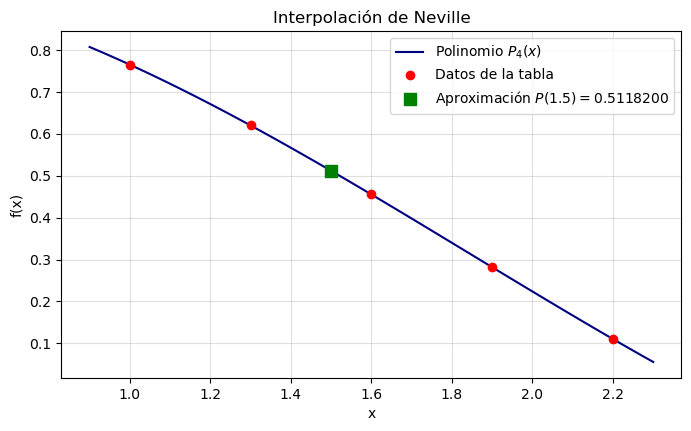

In [ ]:
# Para ver el polinomio completo
x_simbolo = sp.Symbol('x')
polinomio = sp.expand(sp.interpolate(list(zip(x_nodos, y_nodos)), x_simbolo)) #zip para emparejar
res_sympy = float(polinomio.subs(x_simbolo, x_eval))
print("Polinomio interpolador P_4(x) generado con SymPy:")
display(polinomio)

# Para la gráfica de los puntos y la curva interpolada
x_graf = np.linspace(0.9, 2.3, 100)
y_graf = [metodo_neville(val, x_nodos, y_nodos)[1] for val in x_graf]

plt.figure(figsize=(8, 4.5))
plt.plot(x_graf, y_graf, label="Polinomio $P_4(x)$", color="navy")
plt.scatter(x_nodos, y_nodos, color="red", label="Datos de la tabla", zorder=5)
plt.scatter([x_eval], [aproximacion], color="green", marker="s", s=70,
            label=f"Aproximación $P(1.5) = {aproximacion:.7f}$", zorder=6)

plt.title("Interpolación de Neville")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()